# Proyecto Integrador · Avance I: Modelos preliminares de regresión y clasificación
**Proyecto:** HidroClima Ecuador · **Integrantes:** Zayo Vieria, Marlon Benavides, Martin Andrade

## 1. Problema y objetivos
La disponibilidad de lluvia en las cuencas es relevante para estudiar las condiciones de generación hidroeléctrica. Este proyecto explora una primera aproximación para anticipar la precipitación diaria en las zonas de Coca Codo Sinclair y Mazar a partir de las condiciones meteorológicas del día anterior.

| Problema | Variable objetivo | Definición |
|---|---|---|
| Regresión | `precip_manana` | Precipitación del día siguiente, en mm. |
| Clasificación | `lluvia_manana` | 1 si la precipitación del día siguiente es ≥ 5 mm; 0 si es < 5 mm. |

El avance continúa el EDA realizado en **`Entregable1_HidroClima_BD.ipynb`**, de la asignatura **Prácticas y Herramientas de Big Data**. Se mantienen la fuente Open-Meteo Historical Weather API, las dos zonas, las coordenadas, las variables y el periodo **2015-01-01 a 2025-12-31**. Se conservan sus decisiones de limpieza y sus 11 variables candidatas para Machine Learning. Se añade el objetivo numérico para desarrollar la regresión.

Las variables diarias se consideran disponibles al terminar el día: se estudia la predicción del día siguiente. Es una evaluación retrospectiva con datos históricos; no demuestra disponibilidad de reanálisis en tiempo real ni predice caudales o generación eléctrica.

**Contenido:** librerías, continuidad con el EDA, preparación, regresión, clasificación, análisis de resultados y conclusiones. Las tablas, métricas y análisis se calculan en esta ejecución.

## Librerías
Se utilizan pandas y NumPy para los datos, matplotlib y seaborn para las gráficas, y scikit-learn para los modelos y las métricas. Para reproducir la misma copia de datos en Colab, sube `hidroclima_raw.csv` junto al notebook.

In [1]:
import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.autolayout": True})

## 2. Continuidad con el EDA anterior
Se resumen las comprobaciones del EDA que justifican los predictores: calidad de datos, distribución de lluvia, diferencias por zona, estacionalidad y redundancias.

### 2.1 Dataset utilizado
Se mantiene la consulta de Open-Meteo del EDA: mismas variables, coordenadas y periodo. Se utiliza el CSV local si existe; de lo contrario, se descarga. Aunque el EDA describía la fuente como ERA5, su consulta no seleccionaba ese modelo explícitamente. Se conserva la consulta original y se identifica la fuente como **datos históricos de Open-Meteo**.

In [2]:
URL = "https://archive-api.open-meteo.com/v1/archive"
VARIABLES = ("weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,"
             "rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,"
             "wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,"
             "pressure_msl_mean,cloud_cover_mean")
ZONAS = {"Coca Codo Sinclair": (-0.2, -77.68), "Mazar": (-2.59, -78.63)}
CSV = Path("hidroclima_raw.csv")
PROVENIENCIA = Path("hidroclima_proveniencia.json")

def descargar(zona, lat, lon):
    params = {"latitude": lat, "longitude": lon, "start_date": "2015-01-01",
              "end_date": "2025-12-31", "daily": VARIABLES, "timezone": "America/Guayaquil"}
    r = requests.get(URL, params=params, timeout=120)
    r.raise_for_status()
    payload = r.json()
    datos = pd.DataFrame(payload["daily"])
    datos.insert(0, "zona", zona)
    origen = {"zona": zona, "parametros": params,
              "respuesta": {k: payload.get(k) for k in
                  ["latitude", "longitude", "elevation", "timezone", "daily_units"]}}
    return datos, origen

if CSV.exists():
    df_raw = pd.read_csv(CSV)
    print("Se utiliza la copia local:", CSV.name)
else:
    descargas = [descargar(z, lat, lon) for z, (lat, lon) in ZONAS.items()]
    df_raw = pd.concat([d[0] for d in descargas], ignore_index=True)
    df_raw.to_csv(CSV, index=False)
    origen = {"consulta_utc": datetime.now(timezone.utc).isoformat(),
              "url": URL, "modelos": "Best Match (parámetro models no especificado)",
              "consultas": [d[1] for d in descargas],
              "sha256_csv": hashlib.sha256(CSV.read_bytes()).hexdigest()}
    PROVENIENCIA.write_text(json.dumps(origen, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Datos descargados y guardados en", CSV.name)

assert set(df_raw["zona"]) == set(ZONAS), "La copia no contiene las zonas esperadas."
assert set(VARIABLES.split(",")) | {"time", "zona"} == set(df_raw.columns)
print("Dimensiones:", df_raw.shape)


Se utiliza la copia local: hidroclima_raw.csv
Dimensiones: (8036, 16)


El dataset contiene **8036 registros y 16 columnas**, equivalentes a 4018 días por zona, como en el EDA anterior.

### 2.2 Limpieza básica del EDA (renombrar y convertir tipos)

In [3]:
df_eda = df_raw.rename(columns={
    "time": "fecha", "weather_code": "codigo_clima", "temperature_2m_max": "temp_max",
    "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_media",
    "precipitation_sum": "precipitacion", "rain_sum": "lluvia",
    "precipitation_hours": "horas_precipitacion", "relative_humidity_2m_mean": "humedad_media",
    "wind_speed_10m_max": "viento_max", "wind_direction_10m_dominant": "direccion_viento",
    "shortwave_radiation_sum": "radiacion", "et0_fao_evapotranspiration": "evapotranspiracion",
    "pressure_msl_mean": "presion_media", "cloud_cover_mean": "nubosidad_media"})
df_eda["fecha"] = pd.to_datetime(df_eda["fecha"])
df_eda["mes"] = df_eda["fecha"].dt.month

print("Registros por zona:")
print(df_eda["zona"].value_counts())
print("\nPeriodo:", df_eda["fecha"].min().date(), "a", df_eda["fecha"].max().date())
df_eda.head()

Registros por zona:
zona
Coca Codo Sinclair    4018
Mazar                 4018
Name: count, dtype: int64

Periodo: 2015-01-01 a 2025-12-31


,zona,fecha,codigo_clima,temp_max,temp_min,temp_media,precipitacion,lluvia,horas_precipitacion,humedad_media,viento_max,direccion_viento,radiacion,evapotranspiracion,presion_media,nubosidad_media,mes
0,Coca Codo Sinclair,2015-01-01,55,21.3,15.1,18.4,2.4,2.4,6.0,83,8.2,25,19.34,3.47,1014.7,58,1
1,Coca Codo Sinclair,2015-01-02,3,21.2,14.3,17.8,0.0,0.0,0.0,78,7.7,331,12.22,2.44,1015.0,79,1
2,Coca Codo Sinclair,2015-01-03,3,21.5,17.2,19.1,0.0,0.0,0.0,70,6.9,343,14.84,2.94,1015.0,81,1
3,Coca Codo Sinclair,2015-01-04,51,19.9,17.0,18.3,0.4,0.4,2.0,75,4.3,310,7.77,1.67,1016.1,99,1
4,Coca Codo Sinclair,2015-01-05,51,21.5,16.0,18.5,0.5,0.5,3.0,79,7.6,16,14.17,2.66,1015.8,76,1


Se conservan los nombres en español y la conversión de fecha utilizados en el EDA. Cada fila representa un día en una zona.

### 2.3 Calidad de los datos: faltantes, duplicados y redundancias

In [4]:
print("Valores faltantes totales:", int(df_eda.isna().sum().sum()))
print("Duplicados (zona + fecha):", int(df_eda.duplicated(subset=["zona", "fecha"]).sum()))
print("Duplicados (fila completa):", int(df_eda.duplicated().sum()))
print()
print("¿'lluvia' es idéntica a 'precipitacion'?:", bool((df_eda["lluvia"] == df_eda["precipitacion"]).all()))
print("Correlación radiacion vs evapotranspiracion:", round(df_eda["radiacion"].corr(df_eda["evapotranspiracion"]), 2))
print("Correlación temp_media vs temp_max:        ", round(df_eda["temp_media"].corr(df_eda["temp_max"]), 2))
assert not df_eda.duplicated(["zona", "fecha"]).any(), "Hay fechas duplicadas por zona."
assert (df_eda["lluvia"] == df_eda["precipitacion"]).all(), "Revisar la eliminación de lluvia."

Valores faltantes totales: 0
Duplicados (zona + fecha): 0
Duplicados (fila completa): 0

¿'lluvia' es idéntica a 'precipitacion'?: True
Correlación radiacion vs evapotranspiracion: 0.98
Correlación temp_media vs temp_max:         0.93


Se verifican faltantes, duplicados y redundancias. El EDA reportó cero faltantes y duplicados, igualdad entre `lluvia` y `precipitacion` y correlaciones de 0,98 entre radiación y evapotranspiración y 0,93 entre temperatura media y máxima. Estos hallazgos justifican las exclusiones posteriores.

### 2.4 Estadísticas por zona

In [5]:
resumen = (df_eda.groupby("zona")
           .agg(precip_media=("precipitacion", "mean"), precip_max=("precipitacion", "max"),
                temp_media=("temp_media", "mean"), humedad=("humedad_media", "mean"),
                dias_5mm=("precipitacion", lambda s: (s >= 5).mean()))
           .round(2))
resumen

,precip_media,precip_max,temp_media,humedad,dias_5mm
zona,,,,,
Coca Codo Sinclair,10.10,131.5,18.45,84.99,0.63
Mazar,6.47,63.3,14.46,86.39,0.46


Las diferencias de precipitación entre Coca Codo Sinclair y Mazar justifican incluir `zona`. `dias_5mm` muestra la proporción de eventos ≥ 5 mm del día actual; el balance del objetivo del día siguiente se calcula después.

### 2.5 Gráficas del EDA

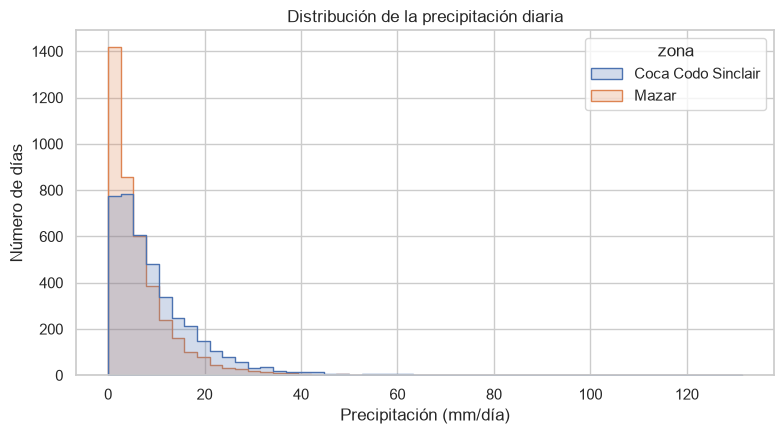

In [6]:
# Histograma de precipitación por zona
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_eda, x="precipitacion", hue="zona", bins=50, element="step", ax=ax)
ax.set_title("Distribución de la precipitación diaria")
ax.set_xlabel("Precipitación (mm/día)")
ax.set_ylabel("Número de días")
plt.show()

La precipitación presenta una distribución sesgada a la derecha. Los pocos eventos intensos pueden dominar el MSE y dificultar su predicción con una regresión lineal.

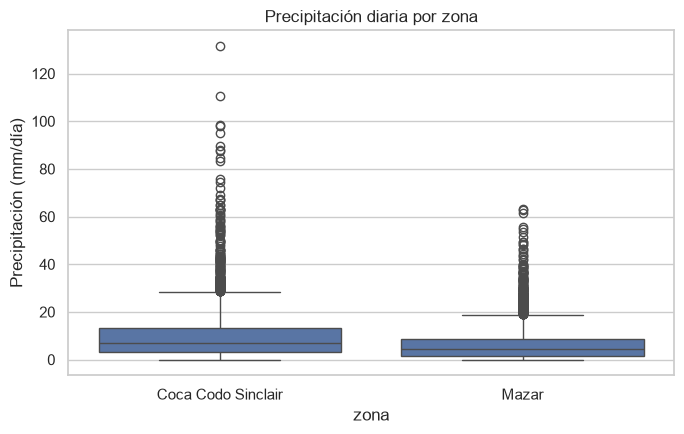

Días atípicos de precipitación (regla IQR) por zona:
zona
Coca Codo Sinclair    196
Mazar                 236
Name: precipitacion, dtype: int64


In [7]:
# Boxplot por zona
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_eda, x="zona", y="precipitacion", ax=ax)
ax.set_title("Precipitación diaria por zona")
ax.set_ylabel("Precipitación (mm/día)")
plt.show()

# Valores atípicos por IQR (se cuentan, NO se eliminan)
def contar_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    return int((s > limite).sum())

print("Días atípicos de precipitación (regla IQR) por zona:")
print(df_eda.groupby("zona")["precipitacion"].apply(contar_atipicos))

Se conservan los valores atípicos, como en el EDA: pueden representar eventos de lluvia intensa relevantes para el problema, y el criterio IQR no demuestra por sí solo que sean errores.

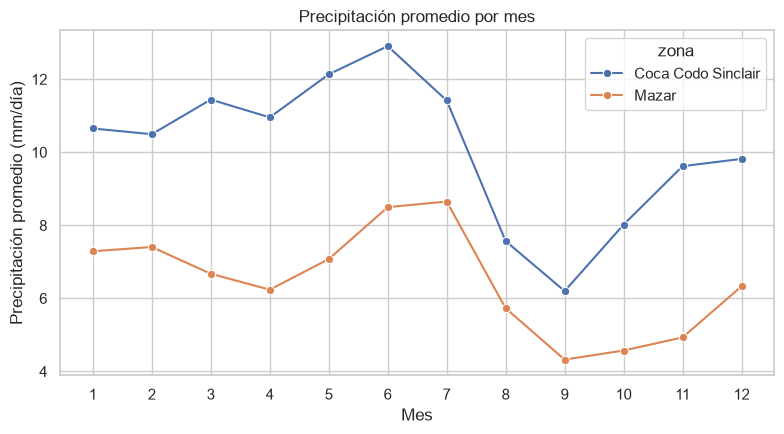

In [8]:
# Promedio mensual de precipitación
mensual = df_eda.groupby(["zona", "mes"])["precipitacion"].mean().reset_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=mensual, x="mes", y="precipitacion", hue="zona", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_title("Precipitación promedio por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación promedio (mm/día)")
plt.show()

La estacionalidad identificada en el EDA justifica incluir `mes`: mayo y junio fueron más lluviosos en Coca Codo Sinclair, y junio y julio en Mazar.

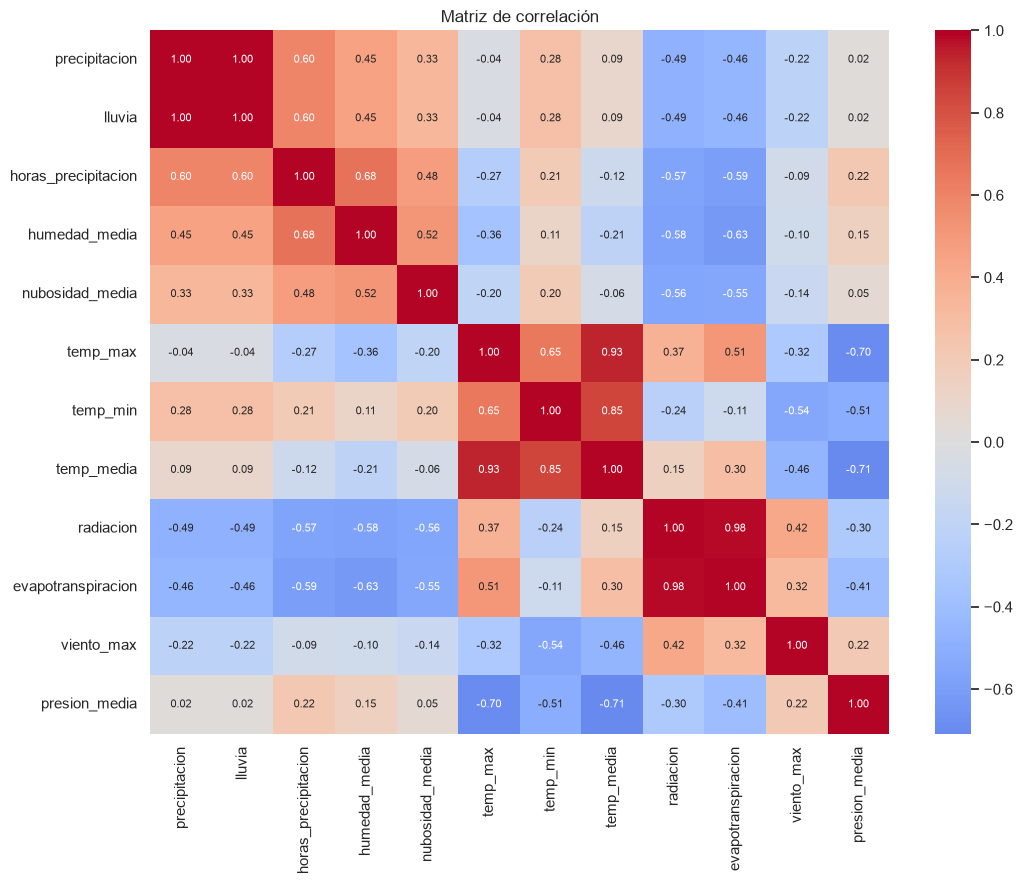

In [9]:
# Matriz de correlación (variables numéricas)
cols_num = ["precipitacion", "lluvia", "horas_precipitacion", "humedad_media", "nubosidad_media",
            "temp_max", "temp_min", "temp_media", "radiacion", "evapotranspiracion",
            "viento_max", "presion_media"]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df_eda[cols_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8}, ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

La matriz confirma redundancias y relaciones entre predictores. En el EDA, las mayores correlaciones con `lluvia_manana` fueron horas de precipitación (0,358), precipitación (0,295) y humedad (0,295). Estas asociaciones orientaron la selección de variables.

## 3. Preparación de los datos

### 3.1 Limpieza: eliminar variables redundantes
Se eliminan las tres columnas descartadas en el Entregable 1:
- `lluvia`: idéntica a `precipitacion`.
- `codigo_clima`: es un resumen de la lluvia del mismo día, que ya está en `precipitacion`.
- `direccion_viento`: es un ángulo (0° y 360° son lo mismo) y no se puede usar como número sin una transformación adicional.

Los **valores atípicos de lluvia se conservan**.

In [10]:
df = df_eda.drop(columns=["lluvia", "codigo_clima", "direccion_viento"])
df = df.sort_values(["zona", "fecha"]).reset_index(drop=True)   # orden cronológico dentro de cada zona

# Comprobación: los días de cada zona son consecutivos (condición para poder usar "el día siguiente")
dias_consecutivos = df.groupby("zona")["fecha"].diff().dropna().eq(pd.Timedelta(days=1)).all()
print("¿Días consecutivos en cada zona?:", bool(dias_consecutivos))
print("Registros antes de crear los objetivos:", len(df))
assert dias_consecutivos, "Hay saltos de fecha: revisar la construcción del día siguiente."
assert df.groupby("zona").size().eq(4018).all(), "Periodo incompleto."
assert df["fecha"].min() == pd.Timestamp("2015-01-01")
assert df["fecha"].max() == pd.Timestamp("2025-12-31")

¿Días consecutivos en cada zona?: True
Registros antes de crear los objetivos: 8036


### 3.2 Creación de las variables objetivo (sin mezclar zonas)
La lluvia del día siguiente se obtiene **desplazando la precipitación un día hacia atrás, por zona** (`groupby("zona").shift(-1)`). Es importante hacerlo por zona y con los datos ordenados por fecha; si no, el último día de Coca Codo Sinclair tomaría como "mañana" el primer día de Mazar.

- `precip_manana` = precipitación del día siguiente (mm).
- `lluvia_manana` = 1 si `precip_manana` ≥ 5 mm, 0 si es menor.

El último día de cada zona (31-dic-2025) no tiene día siguiente, así que su objetivo no existe: **no se puede imputar porque es justamente lo que se quiere predecir**. Se eliminan esas 2 filas (8036 → 8034).

In [11]:
df["fecha_objetivo"] = df.groupby("zona")["fecha"].shift(-1)
df["precip_manana"] = df.groupby("zona")["precipitacion"].shift(-1)
print("Faltantes en precip_manana (último día de cada zona):", int(df["precip_manana"].isna().sum()))

df = df.dropna(subset=["precip_manana"]).reset_index(drop=True)
df["lluvia_manana"] = (df["precip_manana"] >= 5).astype(int)

# Zona como variable numérica 0/1 (Coca Codo Sinclair = 0, Mazar = 1)
df["zona_Mazar"] = (df["zona"] == "Mazar").astype(int)

print("Registros finales:", len(df))
print("\nProporción de días con lluvia significativa mañana (>= 5 mm), por zona:")
print(df.groupby("zona")["lluvia_manana"].mean().round(3))

Faltantes en precip_manana (último día de cada zona): 2
Registros finales: 8034

Proporción de días con lluvia significativa mañana (>= 5 mm), por zona:
zona
Coca Codo Sinclair    0.633
Mazar                 0.456
Name: lluvia_manana, dtype: float64


Se conserva el umbral de 5 mm del EDA, que produjo clases más equilibradas que el umbral de 1 mm. **La clase 0 significa precipitación < 5 mm, no ausencia de lluvia.**

### 3.3 Selección de variables y prevención de *data leakage*

**Variables predictoras (11), todas del día actual:**
`zona_Mazar`, `mes`, `precipitacion`, `horas_precipitacion`, `humedad_media`, `nubosidad_media`, `temp_max`, `temp_min`, `radiacion`, `viento_max`, `presion_media`.

**Variables excluidas y por qué:**

| Variable | Motivo |
|---|---|
| `fecha`, `fecha_objetivo` | Solo identifica el día; su información útil ya está en `mes`. |
| `temp_media` | Correlación ≈ 0,93 con `temp_max`. |
| `evapotranspiracion` | Correlación ≈ 0,98 con `radiacion`. |
| `lluvia`, `codigo_clima`, `direccion_viento` | Eliminadas en la limpieza (redundantes o mal codificadas). |
| `precip_manana`, `lluvia_manana` | Son los objetivos: usarlos como entrada revelaría la respuesta. |

**¿Qué es el data leakage (fuga de datos)?** Es cuando el modelo recibe información que no corresponde utilizar en su evaluación predictiva. Aquí lo evitamos de tres formas: (1) los predictores son solo datos de **hoy**; (2) ningún dato del día siguiente entra como predictor; (3) el imputador y el estandarizador se ajustan **solo con el entrenamiento** (van dentro de un `Pipeline`) y luego se aplican al conjunto de prueba.

In [12]:
X_cols = ["zona_Mazar", "mes", "precipitacion", "horas_precipitacion", "humedad_media",
          "nubosidad_media", "temp_max", "temp_min", "presion_media", "radiacion", "viento_max"]

# Comprobación automática de que ninguna columna objetivo o excluida entró como predictor
prohibidas = {"precip_manana", "lluvia_manana", "fecha", "fecha_objetivo", "temp_media", "evapotranspiracion",
              "lluvia", "codigo_clima", "direccion_viento", "zona"}
assert not (set(X_cols) & prohibidas), "¡Hay variables prohibidas entre los predictores!"
print("Número de predictores:", len(X_cols))
print("Verificado: ningún objetivo ni fecha objetivo se usa como predictor.")

Número de predictores: 11
Verificado: ningún objetivo ni fecha objetivo se usa como predictor.


### 3.4 División temporal entrenamiento / prueba
La partición se realiza por **fecha del evento que se predice** (`fecha_objetivo`):
- Entrenamiento: objetivos del 02/01/2015 al 31/12/2022.
- Prueba: objetivos del 01/01/2023 al 31/12/2025.

Los predictores corresponden al día anterior. Así, las condiciones del 31/12/2022 se reservan para predecir el 01/01/2023 en prueba. Se evita incluir objetivos del periodo de prueba en entrenamiento. No se utiliza una división aleatoria, porque la evaluación busca predecir periodos posteriores con información histórica.

In [13]:
CORTE = pd.Timestamp("2023-01-01")
train = df.loc[df["fecha_objetivo"] < CORTE].copy()
test = df.loc[df["fecha_objetivo"] >= CORTE].copy()
assert train["fecha_objetivo"].max() < test["fecha_objetivo"].min()
assert train["fecha_objetivo"].max() < test["fecha"].min() + pd.Timedelta(days=1)
assert len(train) + len(test) == len(df)

particion = pd.DataFrame([
    {"Conjunto": nombre, "Inicio predictores": g["fecha"].min().date(),
     "Fin predictores": g["fecha"].max().date(),
     "Inicio objetivos": g["fecha_objetivo"].min().date(),
     "Fin objetivos": g["fecha_objetivo"].max().date(), "Registros": len(g)}
    for nombre, g in [("Entrenamiento", train), ("Prueba", test)]])
display(particion)

X_train, X_test = train[X_cols], test[X_cols]
y_train_reg, y_test_reg = train["precip_manana"], test["precip_manana"]
y_train_clf, y_test_clf = train["lluvia_manana"], test["lluvia_manana"]
print("Proporción de clase 1: entrenamiento", round(y_train_clf.mean(), 3),
      "| prueba", round(y_test_clf.mean(), 3))
print("Clases en prueba:", y_test_clf.value_counts().sort_index().to_dict())

,Conjunto,Inicio predictores,Fin predictores,Inicio objetivos,Fin objetivos,Registros
0,Entrenamiento,2015-01-01,2022-12-30,2015-01-02,2022-12-31,5842
1,Prueba,2022-12-31,2025-12-30,2023-01-01,2025-12-31,2192


Proporción de clase 1: entrenamiento 0.545 | prueba 0.542
Clases en prueba: {0: 1004, 1: 1188}


La tabla distingue fechas de predictores y objetivos. La imputación y estandarización se ajustan solo con entrenamiento; la prueba se reserva para evaluar los modelos.

## 4. Regresión: ¿cuánta lluvia habrá mañana?

**Modelo:** Regresión lineal múltiple, usada como modelo base. Antes se imputan faltantes con la mediana (no hay faltantes ahora, pero evita que falle si una consulta futura a la API viene incompleta) y se **estandarizan** las variables para que los coeficientes sean comparables entre sí. Todo va en un `Pipeline` que se ajusta solo con el entrenamiento.

La variable categórica `zona` ya está codificada como 0/1 (`zona_Mazar`), porque la regresión lineal solo trabaja con números.

In [14]:
reg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
reg.fit(X_train, y_train_reg)
y_pred_reg = reg.predict(X_test)

metricas_reg = pd.Series({
    "MSE": mean_squared_error(y_test_reg, y_pred_reg),
    "RMSE (mm)": mean_squared_error(y_test_reg, y_pred_reg) ** 0.5,
    "MAE (mm)": mean_absolute_error(y_test_reg, y_pred_reg),
    "R2": r2_score(y_test_reg, y_pred_reg)})
metricas_reg.round(3)

MSE          48.318
RMSE (mm)     6.951
MAE (mm)      4.959
R2            0.127
dtype: float64

**Métricas:** MSE mide el error cuadrático promedio (mm²), RMSE su raíz (mm) y MAE el error absoluto promedio (mm). R² compara el error con la variabilidad de los valores reales de prueba: cuanto más cercano a 1, mejor ajuste; puede ser negativo. La referencia siguiente predice la media de entrenamiento.

### 4.1 Comparación con un modelo de referencia y resultados por zona

In [15]:
pred_media = np.full(len(test), y_train_reg.mean())
comparacion_reg = pd.DataFrame({
    "Regresión lineal": [mean_squared_error(y_test_reg, y_pred_reg), r2_score(y_test_reg, y_pred_reg)],
    "Promedio de entrenamiento": [mean_squared_error(y_test_reg, pred_media), r2_score(y_test_reg, pred_media)]},
    index=["MSE", "R2"])
display(comparacion_reg.round(3))
mejora = 1 - mean_squared_error(y_test_reg, y_pred_reg) / mean_squared_error(y_test_reg, pred_media)
r2_zonas = pd.Series({zona: r2_score(g["precip_manana"], g["pred"])
    for zona, g in test.assign(pred=y_pred_reg).groupby("zona")}, name="R2")
display(r2_zonas.round(3))

,Regresión lineal,Promedio de entrenamiento
MSE,48.318,56.409
R2,0.127,-0.019


Coca Codo Sinclair    0.060
Mazar                 0.179
Name: R2, dtype: float64

La regresión obtiene **R² 0.127** y reduce el MSE en **14.3%** frente al promedio de entrenamiento. Aprende algunas relaciones, pero su capacidad predictiva es limitada. Por zona, el R² es 0.060 en Coca Codo Sinclair y 0.179 en Mazar.

### 4.2 Gráficas de la regresión

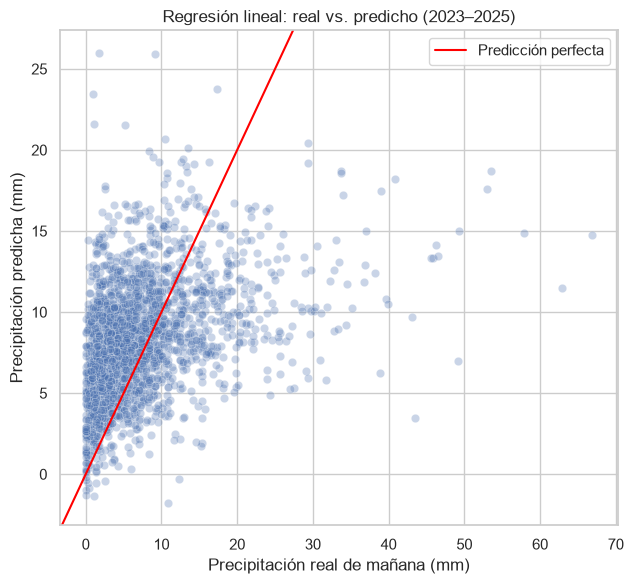

Días con predicción negativa: 11
Predicción máxima: 26.0 mm | Lluvia real máxima: 66.9 mm


In [17]:
fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, alpha=0.3, ax=ax)
ax.axline((0, 0), slope=1, color="red", label="Predicción perfecta")
ax.set_xlabel("Precipitación real de mañana (mm)")
ax.set_ylabel("Precipitación predicha (mm)")
ax.set_title("Regresión lineal: real vs. predicho (2023–2025)")
ax.legend()
plt.show()

print("Días con predicción negativa:", int((y_pred_reg < 0).sum()))
print("Predicción máxima:", round(y_pred_reg.max(), 1), "mm | Lluvia real máxima:", y_test_reg.max(), "mm")

La predicción máxima es **26.0 mm**, frente a **66.9 mm** observados, y aparecen **11 predicciones negativas**. Esto evidencia dificultades para representar lluvias intensas y respetar el límite físico de cero.

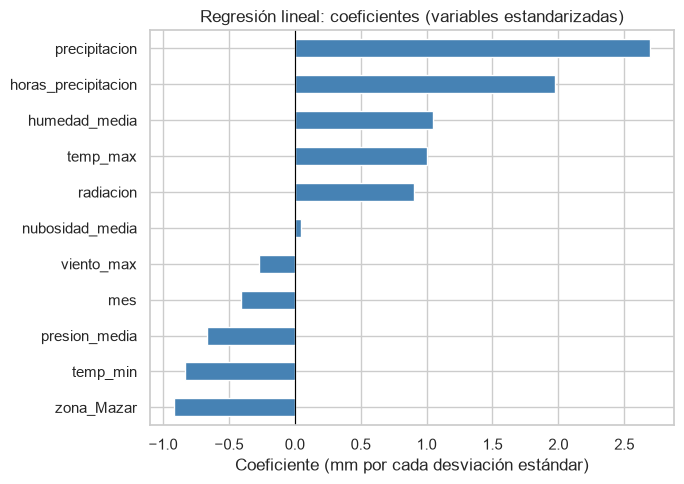

zona_Mazar            -0.917
temp_min              -0.832
presion_media         -0.668
mes                   -0.411
viento_max            -0.271
nubosidad_media        0.044
radiacion              0.907
temp_max               1.002
humedad_media          1.049
horas_precipitacion    1.972
precipitacion          2.697
dtype: float64

In [19]:
coef_reg = pd.Series(reg[-1].coef_, index=X_cols).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
coef_reg.plot.barh(ax=ax, color="steelblue")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión lineal: coeficientes (variables estandarizadas)")
ax.set_xlabel("Coeficiente (mm por cada desviación estándar)")
plt.show()
coef_reg.round(3)

La precipitación, las horas de precipitación y la humedad tienen coeficientes positivos. Los coeficientes describen asociaciones condicionadas a las demás variables; sus magnitudes no demuestran causalidad ni importancia independiente, especialmente con predictores correlacionados.

## 5. Clasificación: ¿habrá lluvia significativa mañana?

**Modelo:** Regresión logística (a pesar del nombre, es un modelo de clasificación): calcula una probabilidad y predice 1 (lluvia ≥ 5 mm) si es mayor a 0,5. Mismas 11 variables, mismo preprocesamiento y misma división temporal que en la regresión.

In [21]:
clf = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train_clf)
y_pred_clf = clf.predict(X_test)

metricas_clf = pd.Series({
    "Accuracy": accuracy_score(y_test_clf, y_pred_clf),
    "Precision": precision_score(y_test_clf, y_pred_clf),
    "Recall": recall_score(y_test_clf, y_pred_clf),
    "F1": f1_score(y_test_clf, y_pred_clf)})
print(metricas_clf.round(3))
print()
print(classification_report(y_test_clf, y_pred_clf, target_names=["Precipitación <5 mm", "Precipitación >=5 mm"]))

Accuracy     0.654
Precision    0.658
Recall       0.751
F1           0.702
dtype: float64

                      precision    recall  f1-score   support

 Precipitación <5 mm       0.65      0.54      0.59      1004
Precipitación >=5 mm       0.66      0.75      0.70      1188

            accuracy                           0.65      2192
           macro avg       0.65      0.64      0.64      2192
        weighted avg       0.65      0.65      0.65      2192



**Métricas:** accuracy mide el total de aciertos; precisión, la proporción de eventos ≥ 5 mm entre las predicciones positivas; recall, la proporción de esos eventos detectada; y F1, la media armónica entre precisión y recall.

### 5.1 Comparación con modelos de referencia (baselines)

In [22]:
# Baseline 1 (persistencia): "mañana habrá lluvia significativa si hoy la hubo"
pred_persist = (test["precipitacion"] >= 5).astype(int)
# Baseline 2 (clase mayoritaria): siempre predecir la clase más frecuente del entrenamiento
clase_mayoritaria = int(y_train_clf.mode()[0])
pred_mayor = np.full(len(test), clase_mayoritaria)

def fila(nombre, pred):
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_test_clf, pred),
            "Precision": precision_score(y_test_clf, pred, zero_division=0),
            "Recall": recall_score(y_test_clf, pred, zero_division=0),
            "F1": f1_score(y_test_clf, pred, zero_division=0)}

tabla_clf = pd.DataFrame([fila("Regresión logística", y_pred_clf),
                          fila("Referencia: persistencia", pred_persist),
                          fila(f"Referencia: siempre clase {clase_mayoritaria}", pred_mayor)]).set_index("Modelo").round(3)
tabla_clf

,Accuracy,Precision,Recall,F1
Modelo,,,,
Regresión logística,0.654,0.658,0.751,0.702
Referencia: persistencia,0.630,0.658,0.658,0.658
Referencia: siempre clase 1,0.542,0.542,1.000,0.703


La logística supera a la persistencia en **2.42 puntos porcentuales de accuracy** y **4.33 puntos de F1**. Sin embargo, la clase mayoritaria obtiene F1 **0.703**, frente a **0.702** de la logística: la mejora depende de la métrica y la referencia.

### 5.2 Matriz de confusión

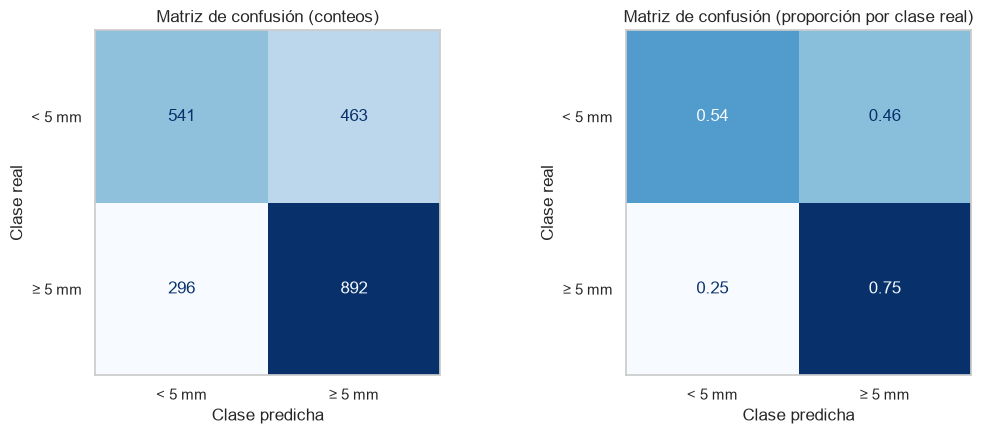

Verdaderos negativos (<5 mm bien detectado): 541
Falsas alarmas (predijo ≥5 mm, fue <5 mm):  463
Eventos ≥5 mm no detectados:                      296
Verdaderos positivos (lluvia detectada):    892


In [24]:
cm = confusion_matrix(y_test_clf, y_pred_clf)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["< 5 mm", "≥ 5 mm"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay.from_predictions(y_test_clf, y_pred_clf, normalize="true",
                                        display_labels=["< 5 mm", "≥ 5 mm"],
                                        ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Matriz de confusión (proporción por clase real)")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos (<5 mm bien detectado): {tn}")
print(f"Falsas alarmas (predijo ≥5 mm, fue <5 mm):  {fp}")
print(f"Eventos ≥5 mm no detectados:                      {fn}")
print(f"Verdaderos positivos (lluvia detectada):    {tp}")

Se detectan **892 de 1188 eventos ≥ 5 mm (75.1%)**, con **463 falsas alarmas** y **296 eventos no detectados**. Se reconoce el 53.9% de los eventos < 5 mm; por tanto, el modelo tiene más dificultad con esta clase.

In [26]:
por_zona = pd.DataFrame({zona: {
    "recall_ge5mm": recall_score(g["lluvia_manana"], g["pred"]),
    "recall_lt5mm": recall_score(g["lluvia_manana"], g["pred"], pos_label=0),
    "accuracy": accuracy_score(g["lluvia_manana"], g["pred"])}
    for zona, g in test.assign(pred=y_pred_clf).groupby("zona")}).T
por_zona.round(3)

,recall_ge5mm,recall_lt5mm,accuracy
Coca Codo Sinclair,0.830,0.361,0.645
Mazar,0.651,0.673,0.662


El desempeño varía por zona: en Coca Codo Sinclair el recall es **83.0%** para ≥ 5 mm y **36.1%** para < 5 mm. En Mazar es **65.1%** y **67.3%**, respectivamente.

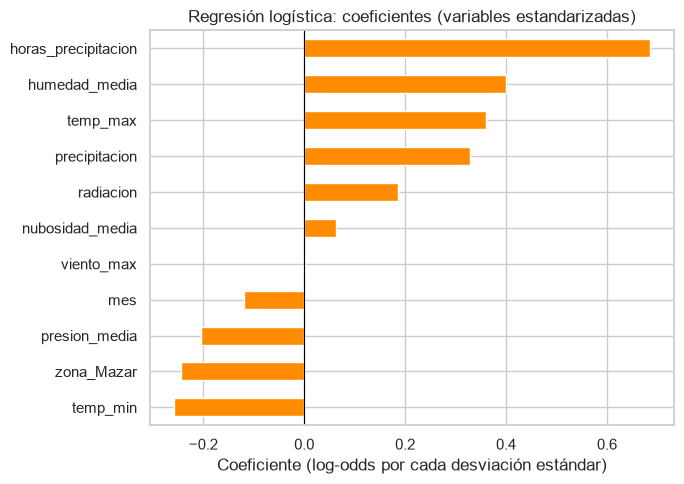

temp_min              -0.258
zona_Mazar            -0.245
presion_media         -0.205
mes                   -0.118
viento_max             0.001
nubosidad_media        0.064
radiacion              0.187
precipitacion          0.330
temp_max               0.360
humedad_media          0.400
horas_precipitacion    0.686
dtype: float64

In [28]:
coef_clf = pd.Series(clf[-1].coef_[0], index=X_cols).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
coef_clf.plot.barh(ax=ax, color="darkorange")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión logística: coeficientes (variables estandarizadas)")
ax.set_xlabel("Coeficiente (log-odds por cada desviación estándar)")
plt.show()
coef_clf.round(3)

Las horas de precipitación y la humedad tienen coeficientes positivos, mientras que `zona_Mazar` tiene coeficiente negativo (-0.245). Son asociaciones dentro del modelo, no relaciones causales ni una medida definitiva de importancia.

## 6. Análisis de resultados y conclusiones
La regresión estima cantidades de lluvia y la clasificación identifica eventos ≥ 5 mm. Sus métricas no son equivalentes: se compara cada modelo con su propia referencia.

In [30]:
resumen_final = pd.DataFrame({
    "Problema": ["Regresión (precip_manana)", "Clasificación (lluvia_manana)"],
    "Modelo": ["Regresión lineal", "Regresión logística"],
    "Métrica principal": ["R2 / RMSE (mm)", "Accuracy / F1"],
    "Resultado": [f"{r2_score(y_test_reg, y_pred_reg):.2f} / {mean_squared_error(y_test_reg, y_pred_reg)**0.5:.1f}",
                  f"{accuracy_score(y_test_clf, y_pred_clf):.2f} / {f1_score(y_test_clf, y_pred_clf):.2f}"],
    "Referencia simple": [f"{r2_score(y_test_reg, pred_media):.2f} / {mean_squared_error(y_test_reg, pred_media)**0.5:.1f} (siempre el promedio)",
                          f"{accuracy_score(y_test_clf, pred_persist):.2f} / {f1_score(y_test_clf, pred_persist):.2f} (persistencia)"]})
resumen_final

,Problema,Modelo,Métrica principal,Resultado,Referencia simple
0,Regresión (precip_manana),Regresión lineal,R2 / RMSE (mm),0.13 / 7.0,-0.02 / 7.5 (siempre el promedio)
1,Clasificación (lluvia_manana),Regresión logística,Accuracy / F1,0.65 / 0.70,0.63 / 0.66 (persistencia)


**Resultados preliminares.** La regresión mejora el MSE del promedio en 14.3%, pero tiene un R² bajo y dificultades con eventos intensos. La clasificación detecta el 75.1% de los eventos ≥ 5 mm, con 463 falsas alarmas. Supera a la persistencia en accuracy y F1, aunque su F1 es ligeramente inferior al de la clase mayoritaria.

**Predictores y preparación.** Se mantienen las 11 variables propuestas en el EDA: zona y mes representan diferencias geográficas y estacionalidad, y las variables meteorológicas describen el día anterior. Las principales dificultades fueron construir objetivos por zona, eliminar sus faltantes y variables redundantes, separar los periodos y conservar lluvias extremas. Las correlaciones entre predictores dificultan interpretar sus coeficientes.

**Mejoras.** Incorporar información de días anteriores, probar modelos no lineales y por zona, y validar con varios cortes temporales antes de ajustar el umbral de clasificación.

**Conclusión.** Se logró una primera aproximación de regresión y clasificación a partir del EDA. Los resultados son modestos y requieren mejoras para aumentar su utilidad predictiva.

**Referencias:** EDA `Entregable1_HidroClima_BD.ipynb` del equipo HidroClima y [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api).